In [1]:
from requirements import *
from utils.tl.score_genes import score_genes

# Figure 5

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)
adata_xenv2 = sc.read_h5ad(XEN_V2)

## Figure 5b. Mean TGFB1 expression, Control vs SF3B1 mutant Mks

In [4]:
sample_mutation_di = {'U2AF1': ['region1_0033266','region1_0065644','region2_0065644','region1_0065647','region2_0065647'], 'ASXL1': ['region1_0033266'],
                      'IDH1': ['region1_0033082'], 'SRSF2': ['region1_0033082'], 'CUX1': ['region1_0033082'],
                      'DNMT3A': ['region1_0033134'], 'SF3B1': ['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']}

samples = sample_mutation_di['SF3B1'] 
allmut = adata_xenv2[(adata_xenv2.obs['mutant'] == 'Yes') & (adata_xenv2.obs['ct_general'] == 'Megakaryocyte')] #.obs.index
allmut = allmut[allmut.obs['sample_name'].isin(samples)]

ctl_ad = adata_xenv2[adata_xenv2.obs['ct_general'] == 'Megakaryocyte']
ctl_ad = ctl_ad[ctl_ad.obs['sample_name'].isin(['region1_0032837','region2_0065574','region3_0065574','region4_0065586'])]

megas = [x for x in allmut.obs.index] + [x for x in ctl_ad.obs.index]
ad_mega = adata_xenv2[adata_xenv2.obs.index.isin(megas)]

ad_mega.obs['patient_id'] = [x.split('T1')[0] for x in ad_mega.obs['patient_id']]

In [7]:
# mean per sample
df = sc.get.obs_df(ad_mega, keys=['TGFB1', 'mutant','patient_id'])
counts = df['patient_id'].value_counts()
keep = counts[counts > 10].index.tolist()
df = df[df['patient_id'].isin(keep)]

df_tgfb = pd.DataFrame(df.groupby('patient_id')['TGFB1'].mean())
di = dict(zip(df['patient_id'], df['mutant']))
df_tgfb['mutant'] = [di[x] for x in df_tgfb.index]
df_tgfb

,TGFB1,mutant
patient_id,,
EDTA016,1.374529,No
EDTA024,0.629394,No
EDTA30,1.147569,No
ND158,2.852031,Yes
ND226,2.020474,Yes
ND62,1.736457,Yes
ND83,2.288793,Yes


## Figure 5h. CD8 Memory cytotoxic gene signature score by proximity to Mk


In [3]:
## Get Xenium output paths

BASE = '/data1/greenbab/users/zhangb2/xenium_files'

def region_key(name):
    """'output__<a>__<b>_<c>...' -> 'region<c>_<a>'"""
    _, a, b = name.split('__')[:3]
    return f"region{b.split('_')[1]}_{a}"

dir_di = {}  # key is region, value is data directory

review_dir = f'{BASE}/review_samples/v1'
for f in os.listdir(review_dir):
    if f.startswith('output'):
        dir_di[region_key(f)] = f'{review_dir}/{f}/'

baysor_dir = f'{BASE}/baysor'
for f in os.listdir(baysor_dir):
    if f.startswith('output'):
        dir_di[region_key(f)] = f'{baysor_dir}/{region_key(f)}/xeniumout/outs/'

In [7]:
# Get original cell IDs of Mks that were merged during segmentation refinement
import json
with open("/data1/greenbab/users/zhangb2/xenium_files/review_samples/pickle/resegment/v1_combined_mega_dictionary.json", "r") as file:
  combined_megas = json.load(file)

In [8]:
combined_megas

{'region1_0011549': [[['ipiabdpm-1', 'ndfpoige-1', 'aaaaffnp-1'],
   [1736.8983178439182, 5902.43668769885]],
  [['aaeldbij-1'], [7852.328889380529, 6048.533679789458]],
  [['aaepejfo-1'], [7363.340411495312, 5976.805802157492]],
  [['aafpfflh-1'], [8274.895724183065, 12837.425928313207]],
  [['aajmabhg-1'], [7516.4542874276, 3228.115077846167]],
  [['aajngobn-1'], [8553.341713476997, 14122.902292091248]],
  [['aoadmdoi-1',
    'acemidmg-1',
    'bkpgdjbd-1',
    'liempocb-1',
    'nbbgodpa-1',
    'aimnkfkl-1',
    'odbhnkpo-1',
    'ehlplbci-1',
    'amncneie-1',
    'ofaeakeb-1',
    'ilblmlde-1',
    'jlblnmki-1',
    'cpaokcgk-1',
    'dmhdeofn-1',
    'ijeeajkm-1',
    'oapjfohb-1',
    'aakbakpc-1',
    'gkmifhma-1',
    'hfjjaenn-1',
    'ikllcmca-1',
    'joneiehp-1',
    'didhokkp-1',
    'bahgkiid-1',
    'bpnpfimp-1',
    'fnnkmilm-1',
    'fliljfmk-1',
    'ohdimhgj-1'],
   [2057.6651658850683, 9652.53450809864]],
  [['aakoakmf-1',
    'dmbolncn-1',
    'kmpliehi-1',
    '

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0011549/xeniumout/outs/


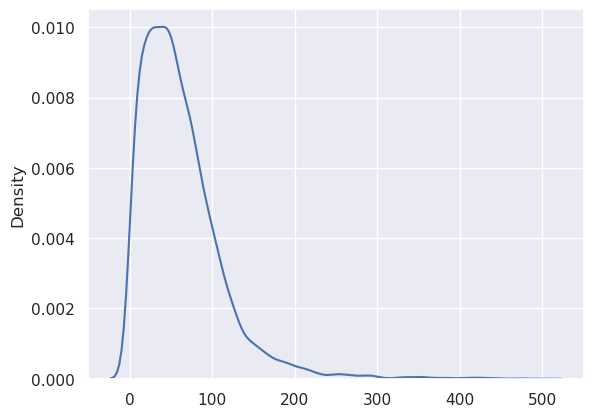

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0011552/xeniumout/outs/


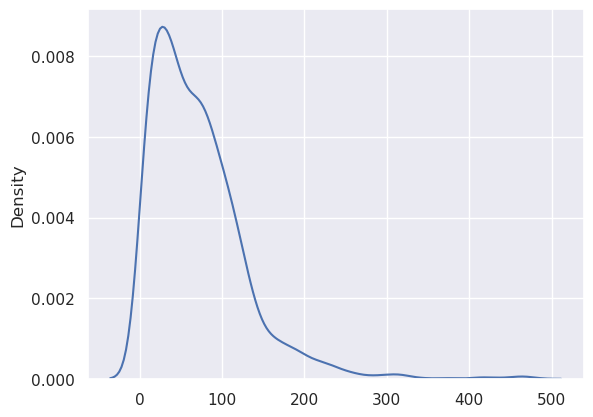

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0011552/xeniumout/outs/


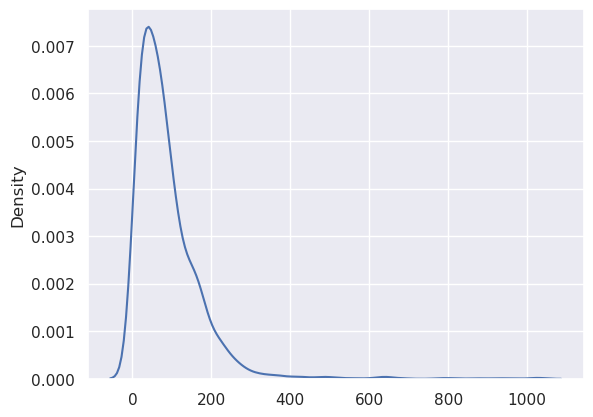

/data1/greenbab/users/zhangb2/xenium_files/baysor/region3_0011552/xeniumout/outs/


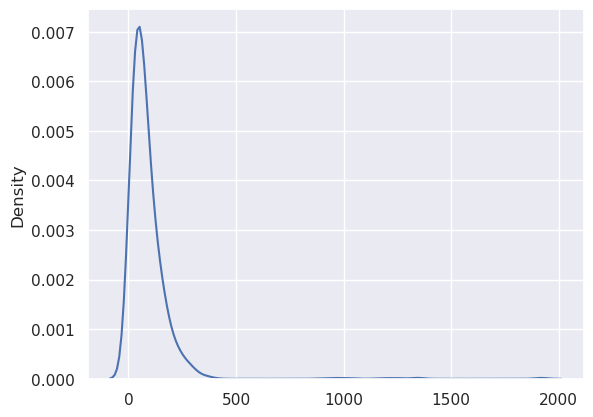

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027612/xeniumout/outs/


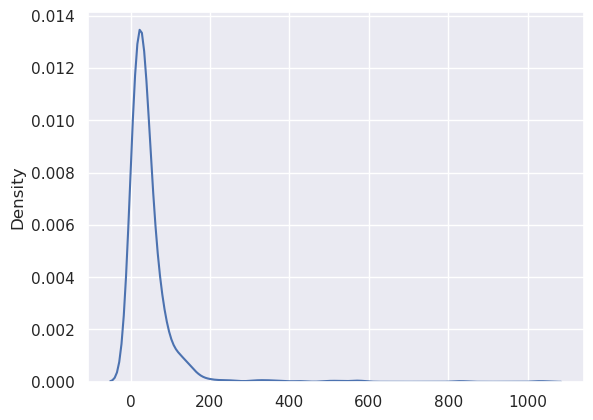

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027609/xeniumout/outs/


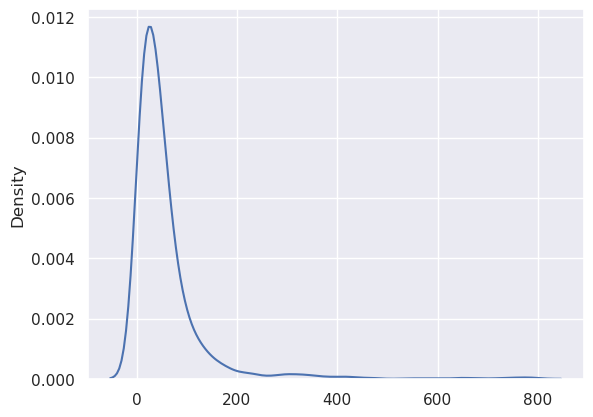

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0015400/xeniumout/outs/


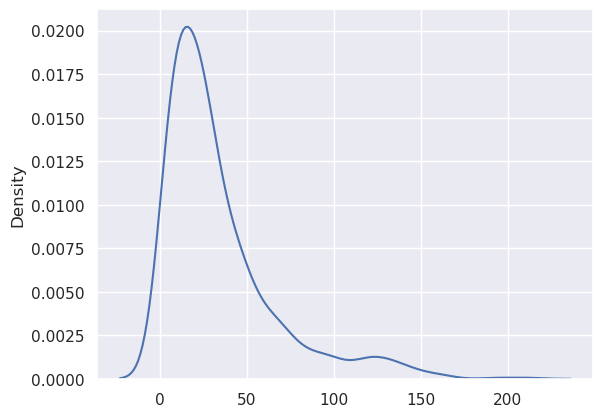

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0015399/xeniumout/outs/


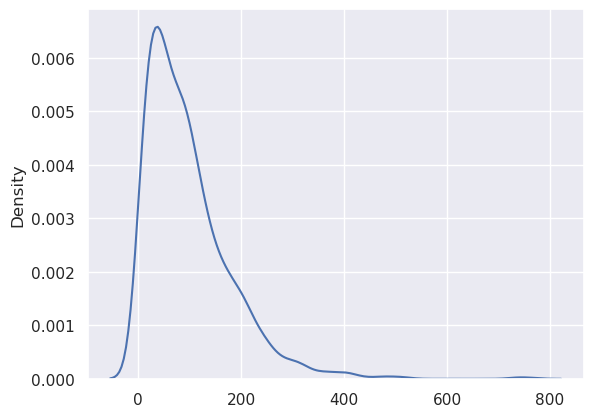

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027860/xeniumout/outs/


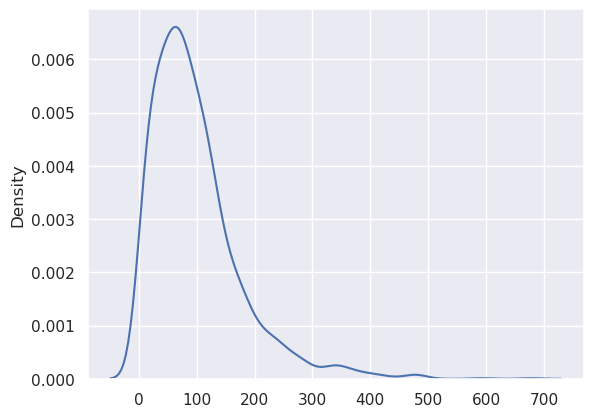

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0027861/xeniumout/outs/


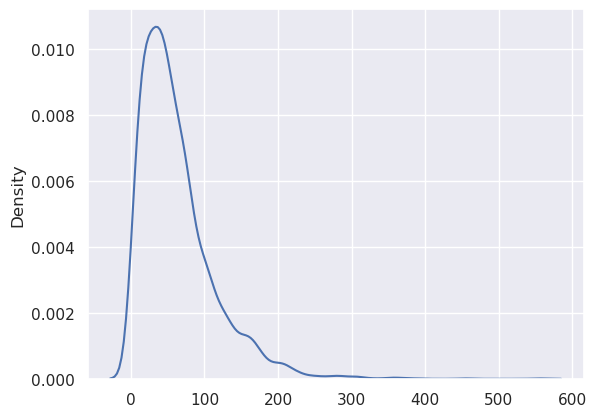

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0043106/xeniumout/outs/


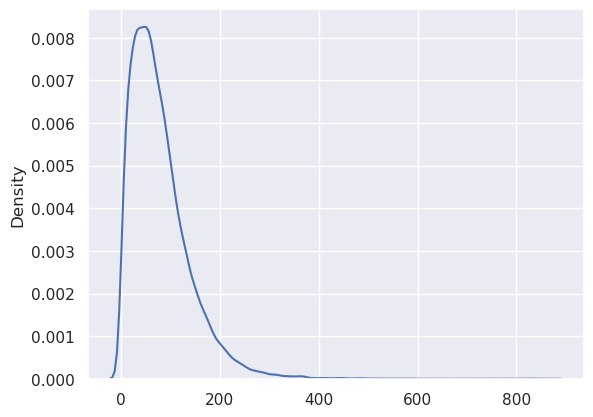

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0043114/xeniumout/outs/


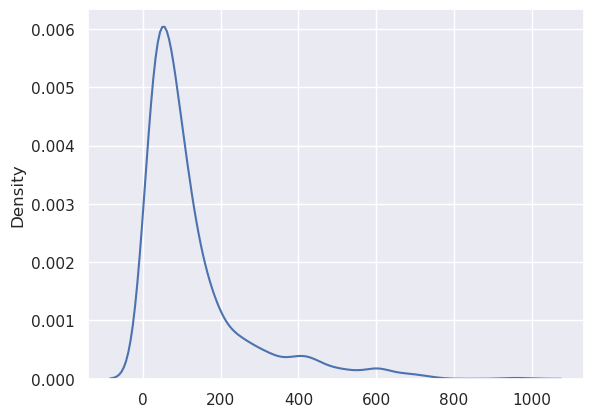

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0036509/xeniumout/outs/


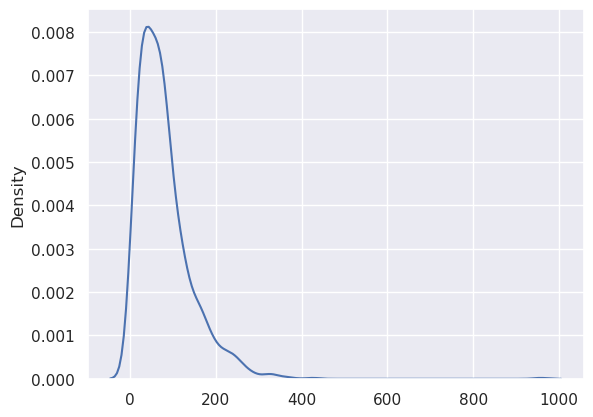

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0036579/xeniumout/outs/


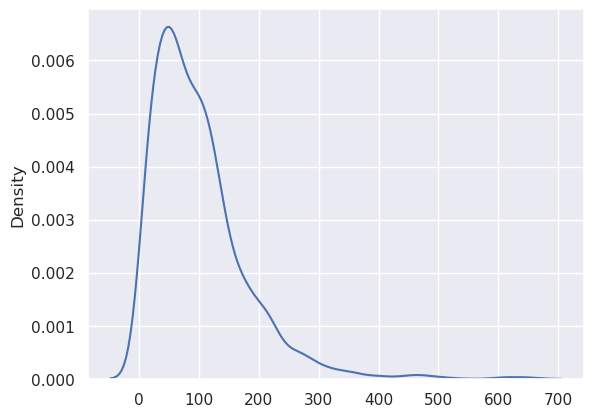

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0042581/xeniumout/outs/


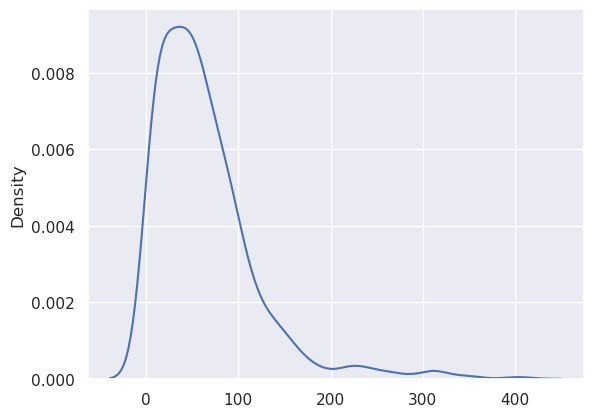

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0033583__Region_1__20250604__183844/


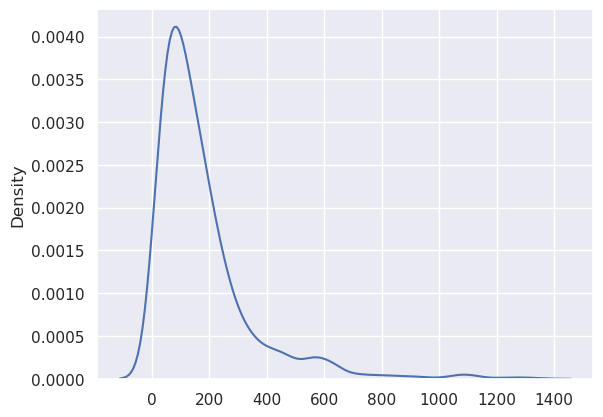

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0033583__Region_2__20250604__183844/


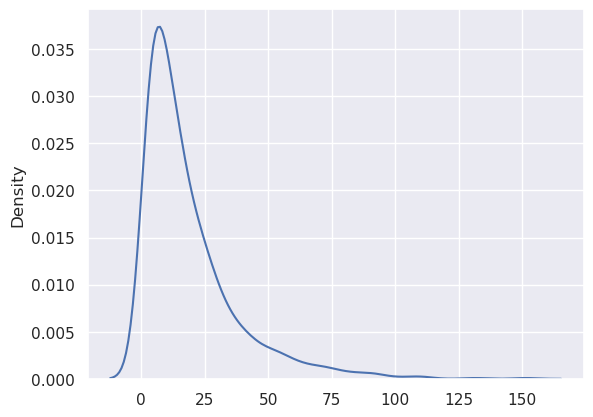

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0042591__Region_2__20250305__185108/


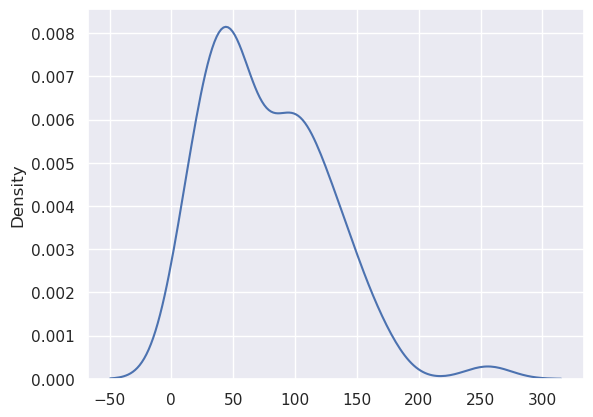

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0042592__Region_1__20250305__185108/


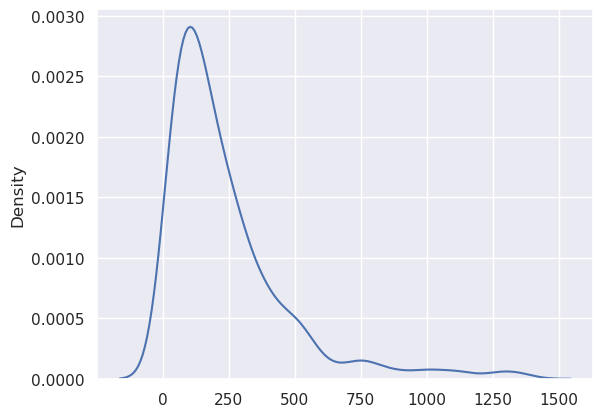

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0064838__Region_1__20250604__183844/


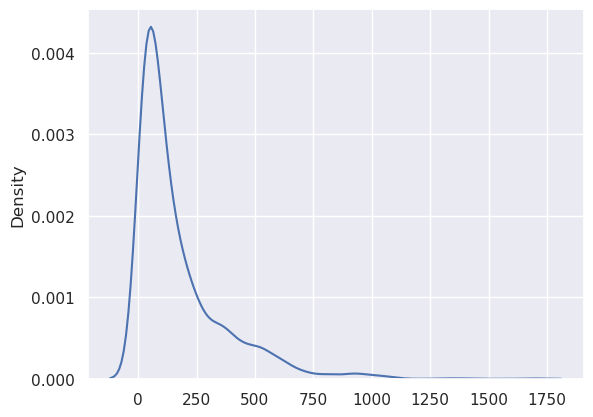

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0064838__Region_2__20250604__183844/


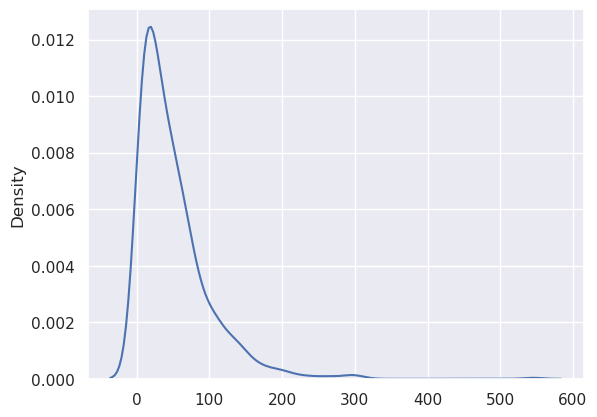

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065604__Region_1__20250523__144423/


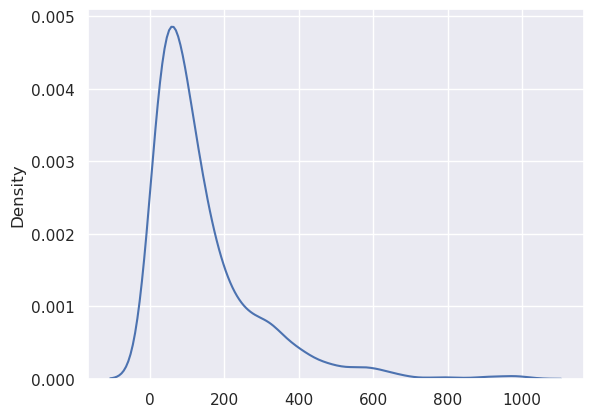

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065604__Region_4__20250523__144423/


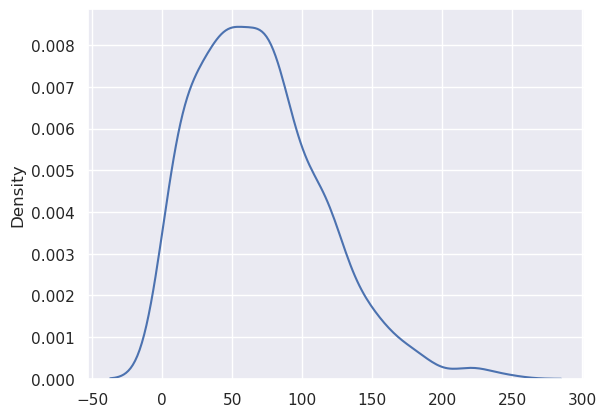

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065607__Region_1__20250523__144423/


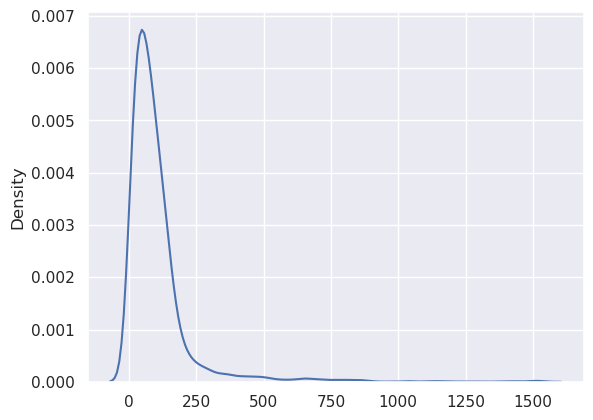

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065607__Region_2__20250523__144423/


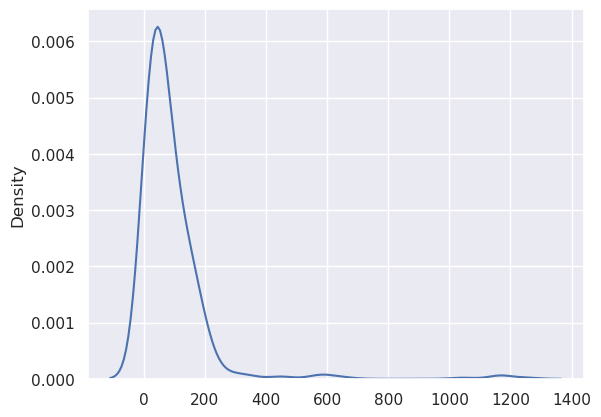

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069145__Region_1__20250801__184414/


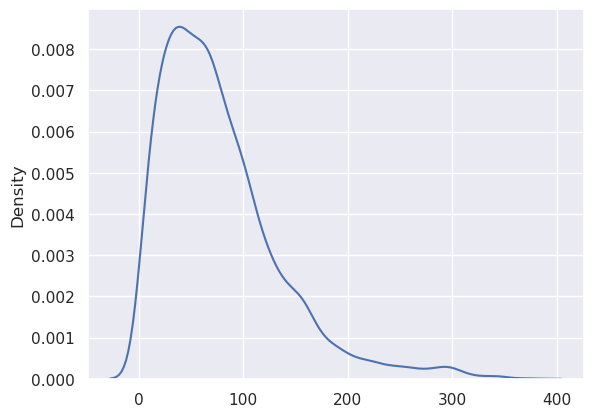

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069145__Region_2__20250801__184414/


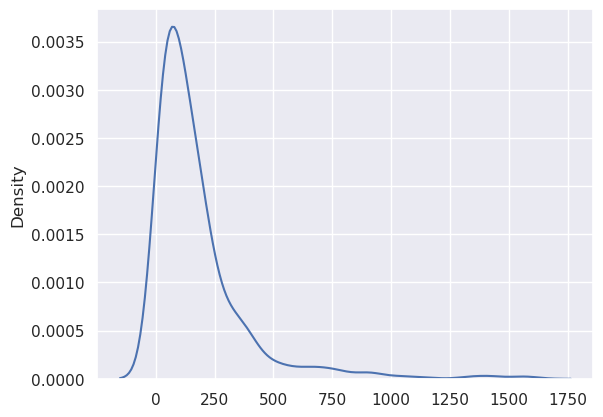

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069146__Region_1__20250801__184414/


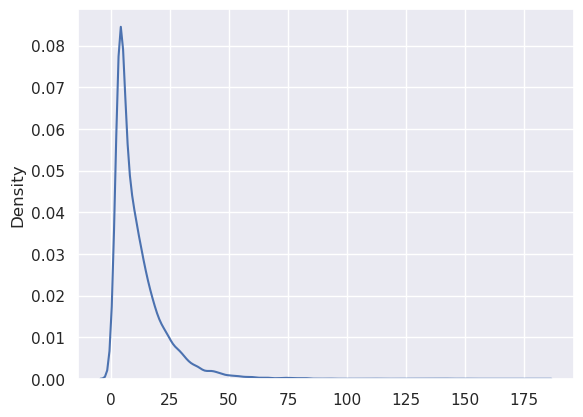

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069146__Region_2__20250801__184414/


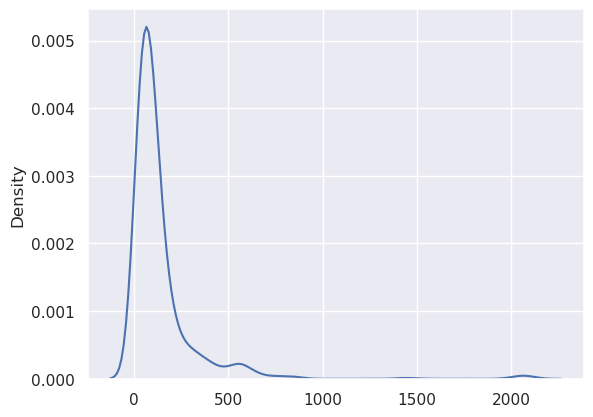

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069319__Region_1__20250822__183944/


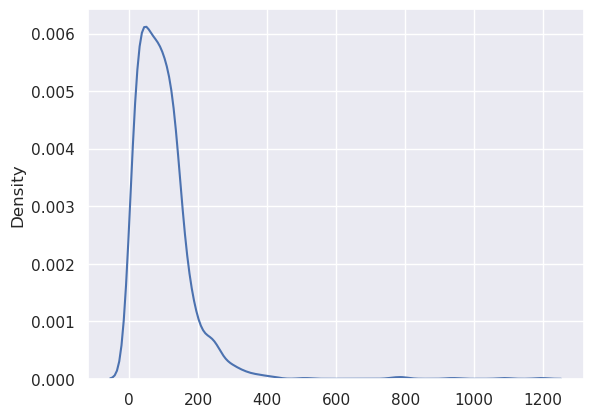

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069319__Region_2__20250822__183944/


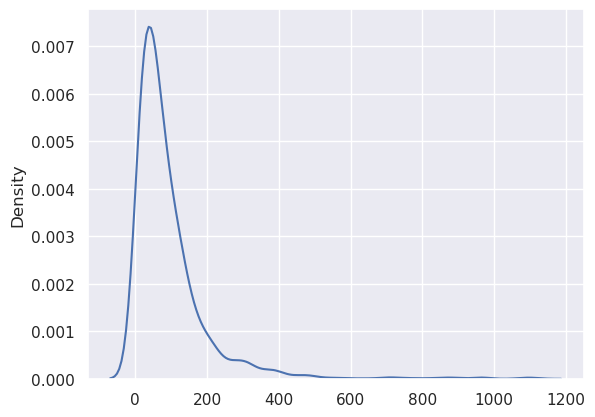

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069320__Region_1__20250822__183944/


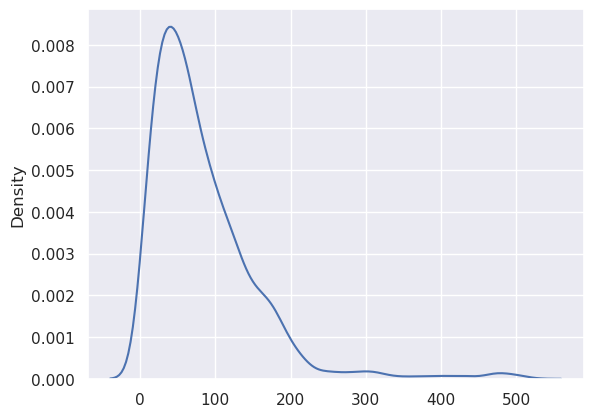

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069320__Region_2__20250822__183944/


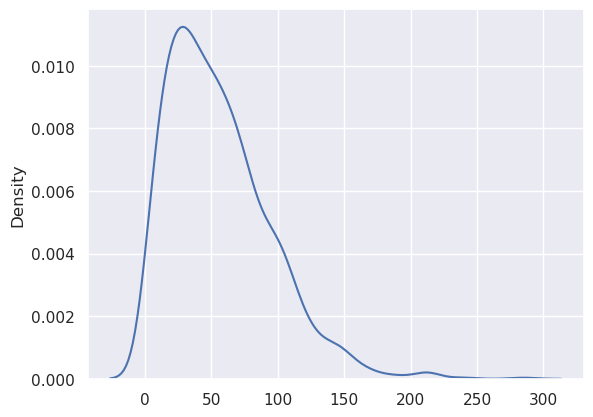

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069330__Region_1__20250815__192418/


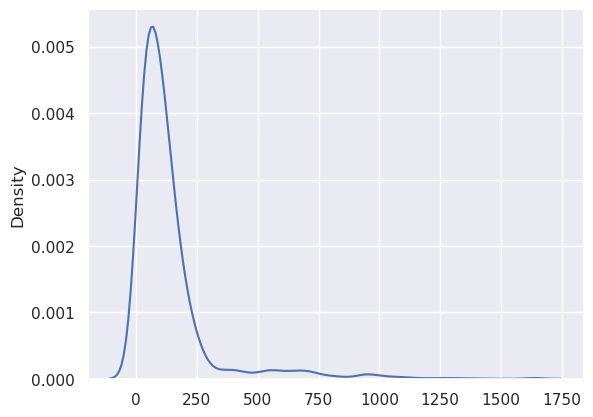

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069331__Region_1__20250815__192418/


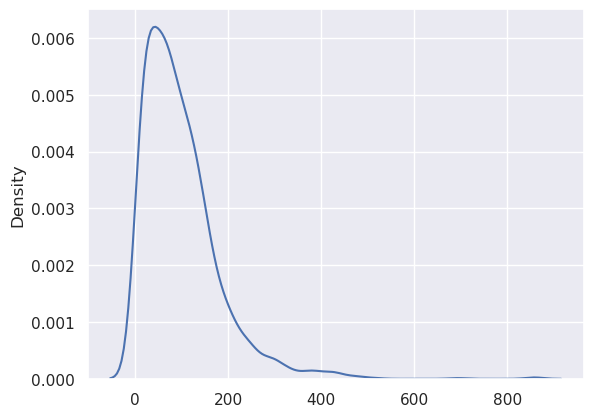

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069670__Region_1__20250808__172051/


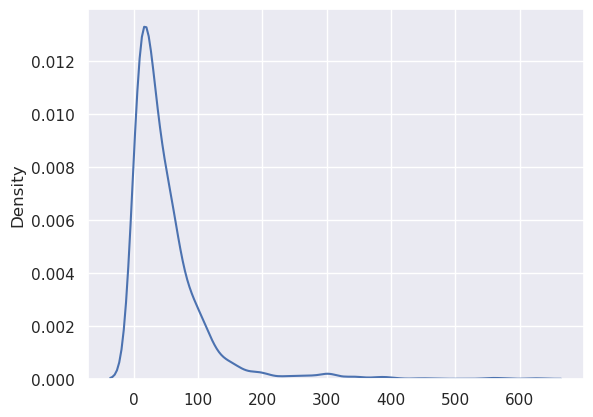

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069737__Region_1__20250808__172052/


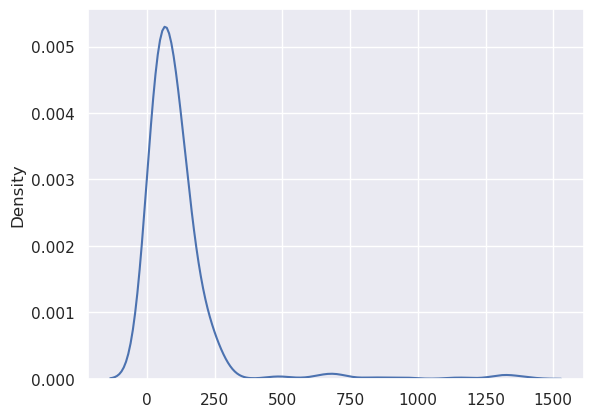

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069737__Region_2__20250808__172052/


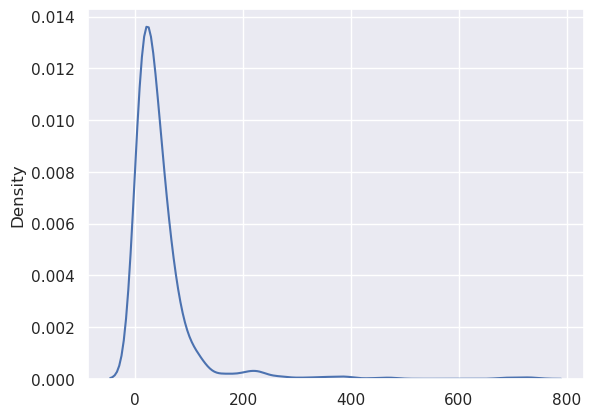

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069187__Region_1__20250808__172538/


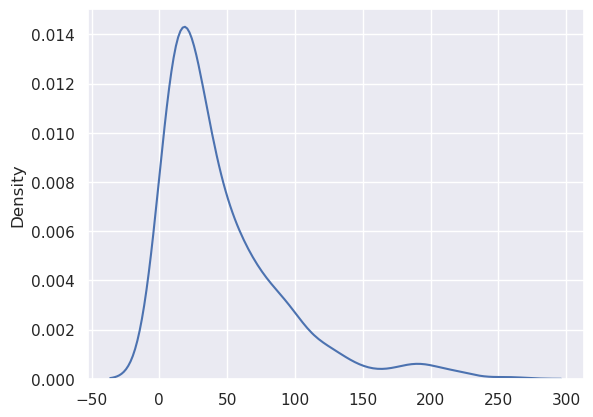

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069478__Region_1__20250815__191843/


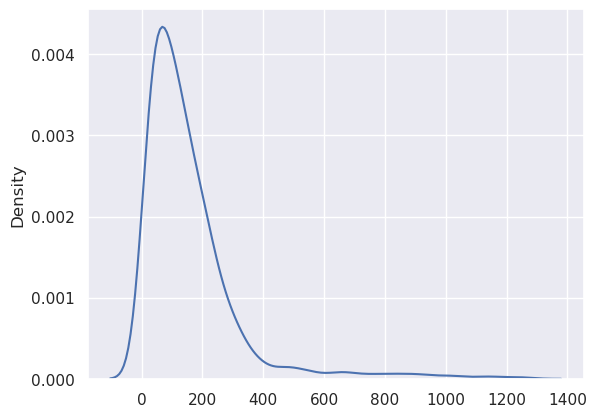

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069478__Region_2__20250815__191843/


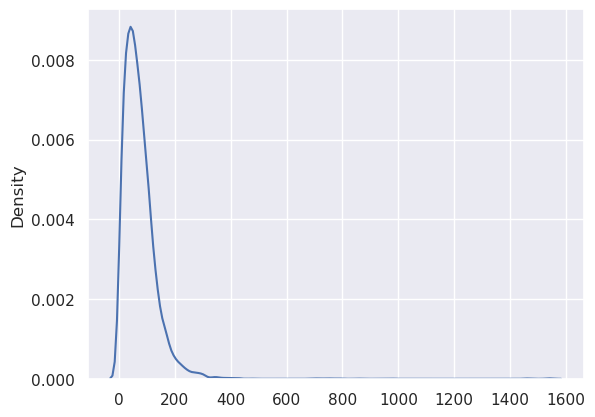

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069480__Region_1__20250815__191843/


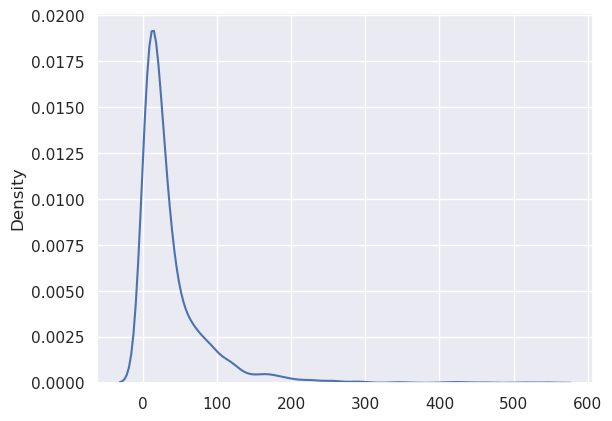

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069594__Region_1__20250822__185706/


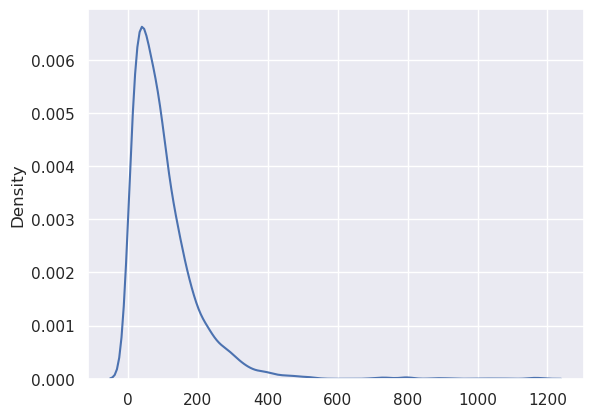

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069594__Region_2__20250822__185707/


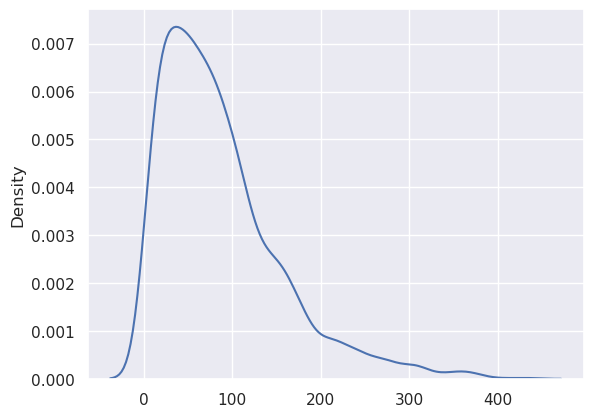

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069595__Region_1__20250822__185707/


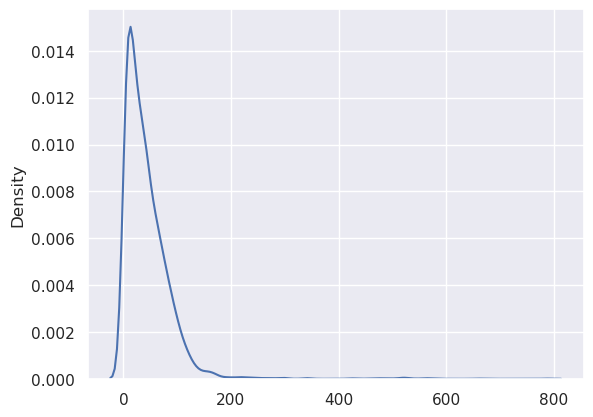

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069595__Region_2__20250822__185707/


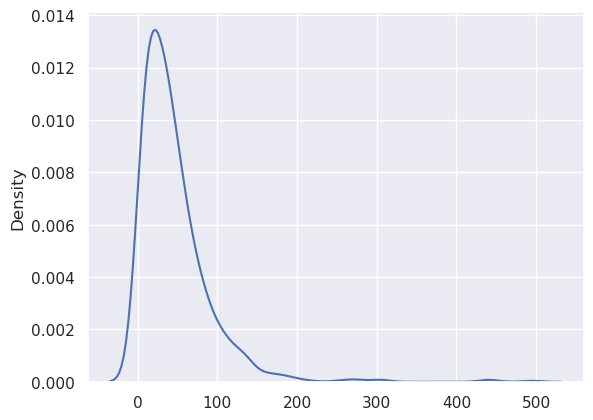

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069641__Region_1__20250808__172538/


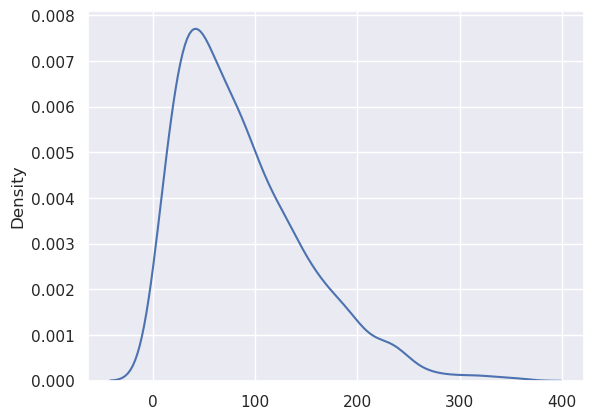

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069641__Region_2__20250808__172538/


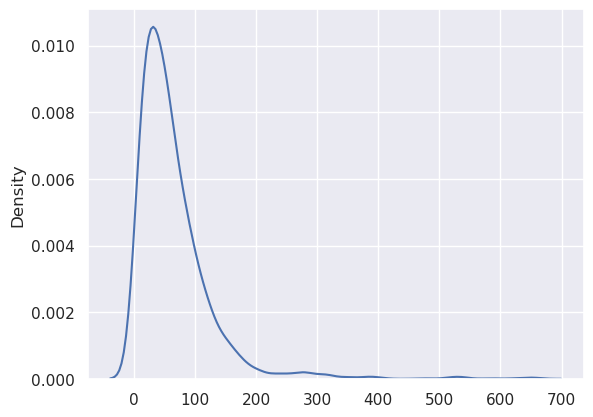

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069808__Region_1__20250904__175644/


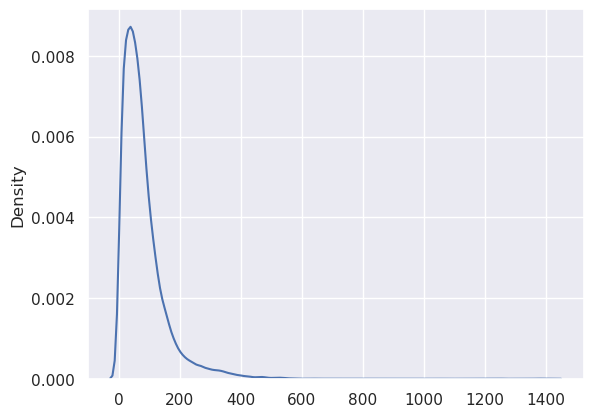

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015858__Region_2__20250904__184740/


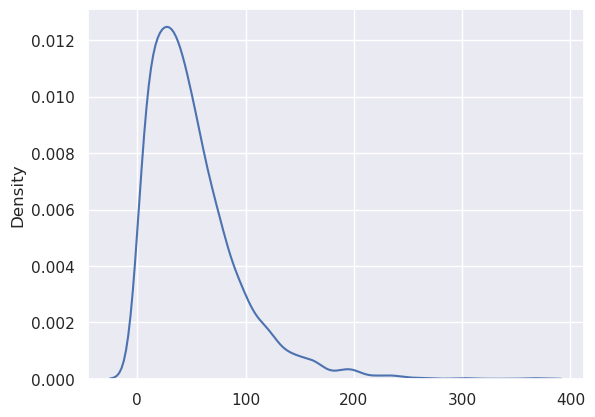

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015858__Region_1__20250904__184740/


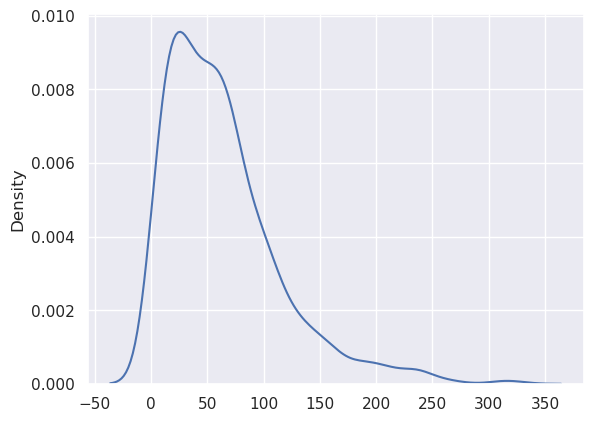

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015829__Region_1__20250904__184739/


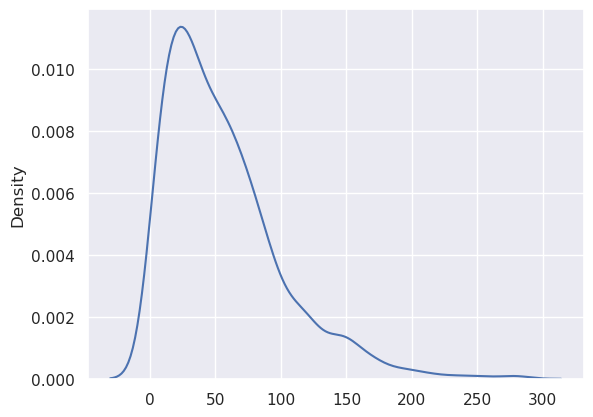

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015829__Region_2__20250904__184740/


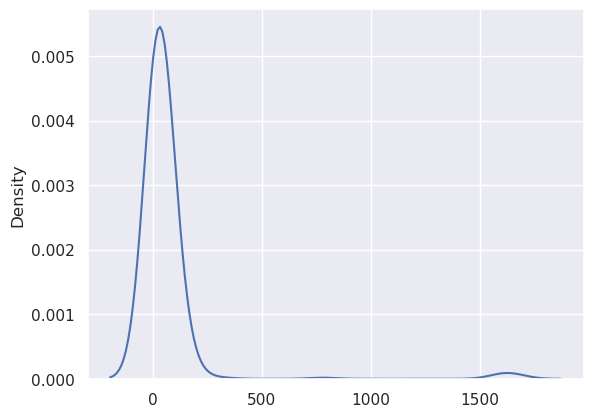

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069665__Region_2__20250904__175644/


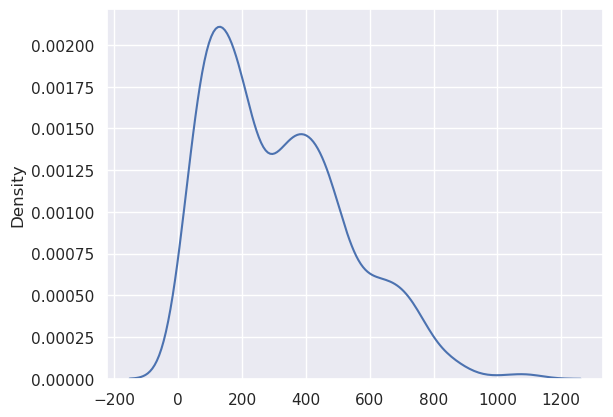

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069665__Region_1__20250904__175644/


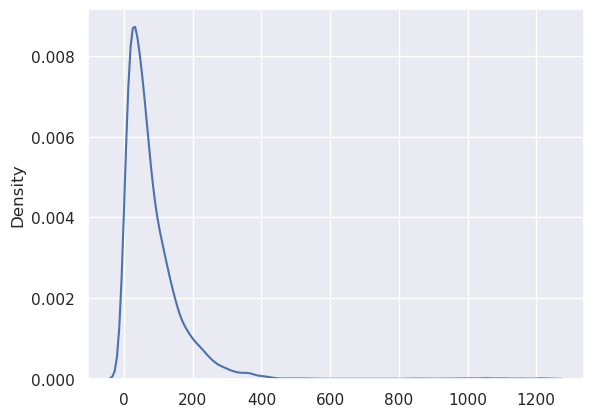

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_3__20251001__202328/


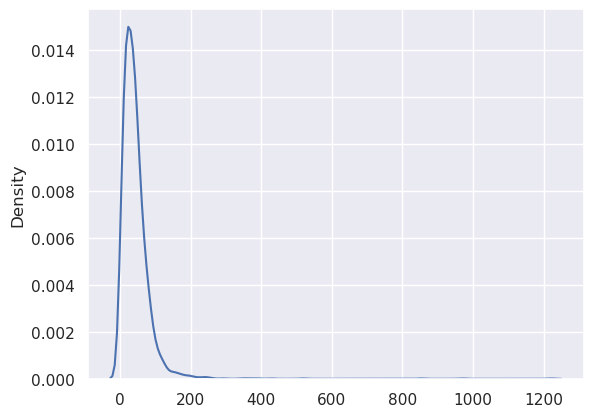

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_2__20251001__202328/


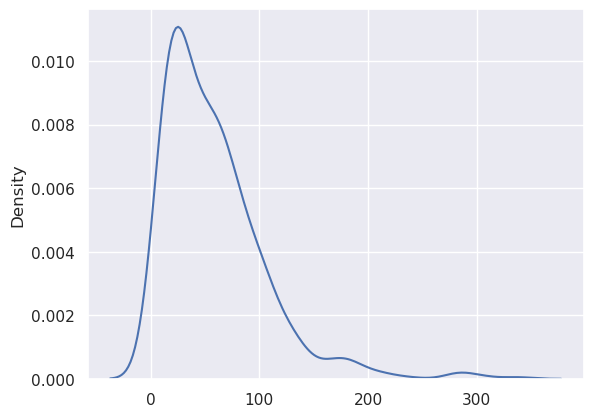

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_3__20251001__202328/


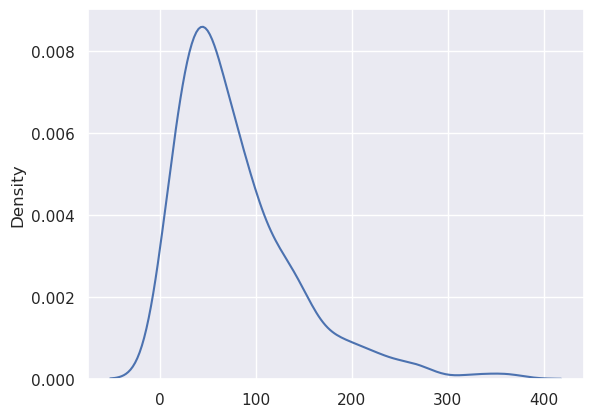

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_1__20251001__202328/


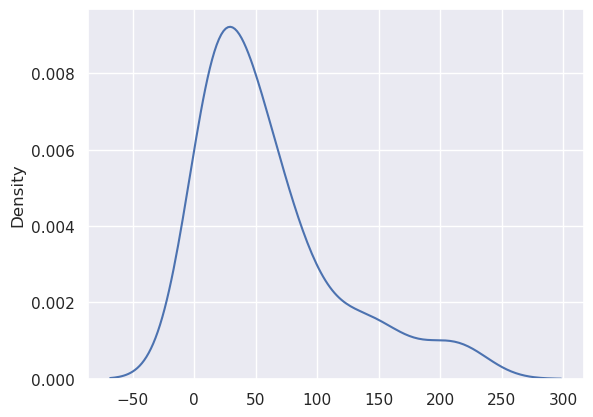

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_1__20251001__202327/


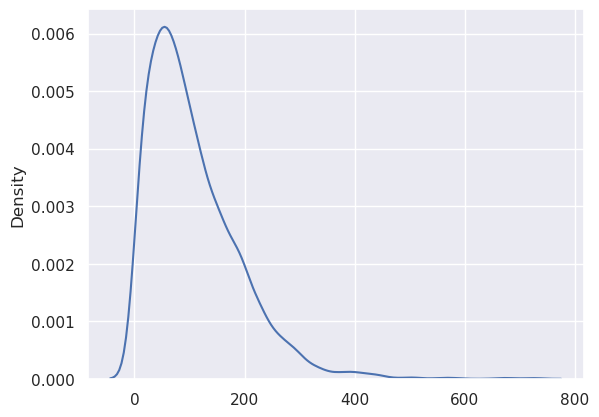

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_2__20251001__202328/


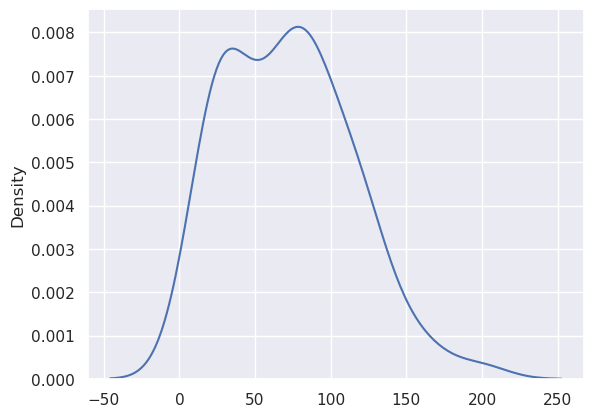

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079272__Region_1__20250926__202419/


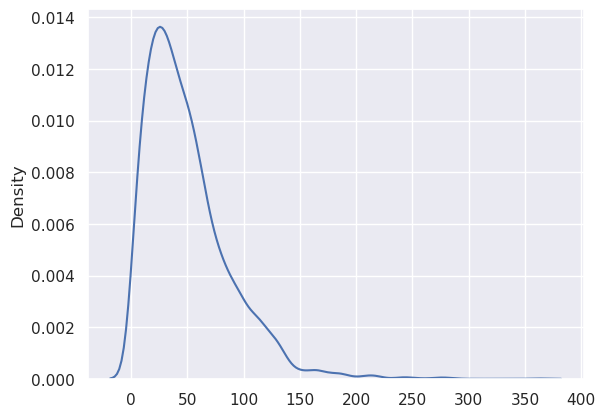

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079272__Region_2__20250926__202419/


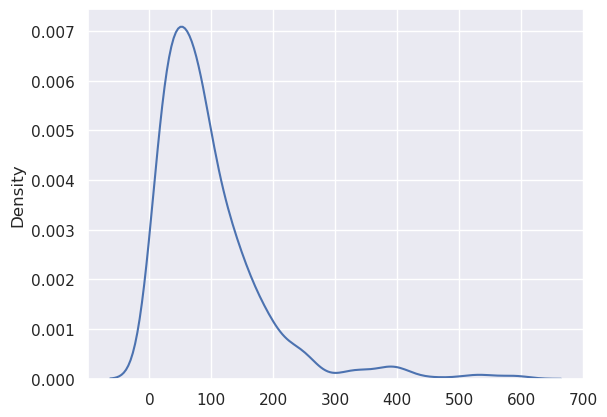

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079269__Region_2__20250926__202419/


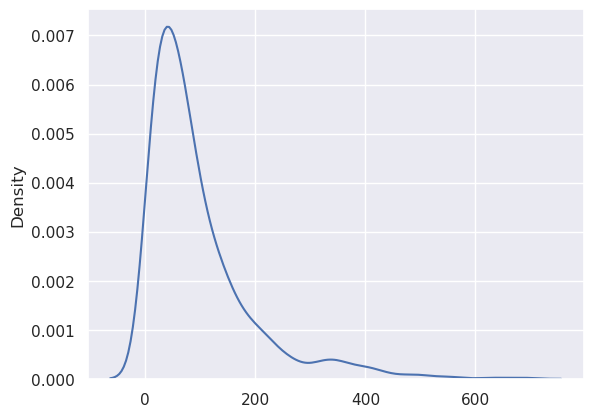

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079269__Region_1__20250926__202419/


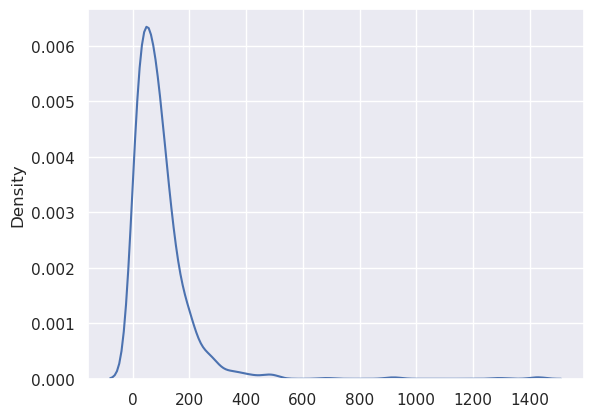

In [10]:
# Compute distance to nearest Mk cell (boundary vertex) for each T cell

di_tdist = dict()

from scipy.spatial import distance_matrix

for currsamp in adata_xenv1.obs['sample_name'].unique():
    ad_samp = adata_xenv1[adata_xenv1.obs['sample_name'] == currsamp]
    megaids = set(ad_samp[ad_samp.obs['ct_general'] == 'Megakaryocyte'].obs['cell_id'])

    replacedi = dict()
    if not currsamp == 'region1_0069146': # the sample with a lot of micro megakaryocytes
        for i,mega in enumerate(combined_megas[currsamp]):
            curr_mega = 'mega-' + str(i)
            for m in mega[0]:
                replacedi[m] = curr_mega
            
    boundary_dir = dir_di[currsamp] 
    print(boundary_dir)
    cell_boundaries = pd.read_csv(boundary_dir + 'cell_boundaries.csv.gz')
    cell_boundaries['new_cell_id'] = [replacedi[x] if x in replacedi else x for x in cell_boundaries['cell_id']]
    mega_vertices = cell_boundaries[(cell_boundaries['new_cell_id'].isin(megaids))]
    
    ad_samp = ad_samp[~ad_samp.obs['cell_id'].isin(megaids)]
    df = ad_samp[ad_samp.obs['ct_general'].isin(['T Cell'])].obs[['x_centroid','y_centroid']] # non-mega cells
    df.columns = ['x','y']
    
    df['cell_id'] = df.index
    df['ct'] = 'Non-mega'
        
    tmp = mega_vertices[['vertex_x', 'vertex_y']]
    tmp.columns = ['x','y']
    tmp['cell_id'] = mega_vertices['new_cell_id']
    tmp['ct'] = 'Mega'
    

    dist = distance_matrix(tmp.loc[:,['x','y']],df.loc[:,['x','y']])
    sns.kdeplot((np.min(dist, axis=0)))
    plt.show()
    samp_idx = adata_xenv1[(adata_xenv1.obs['sample_name'] == currsamp)].obs.index[0].split('-')[-1]
    tmp = [float(x) for x in np.round(np.min(dist, axis=0), 2)]

    currdi = dict(zip(df['cell_id'], tmp))
    di_tdist.update(currdi)

In [10]:
# Compute mean cytotoxic gene signature scores grouped by distance to nearest Mk for each sample

df = pd.DataFrame({'dist': di_tdist.values(),  'id': di_tdist.keys()})

di = dict(zip(adata_xenv1.obs.index, adata_xenv1.obs['ct_refined']))
df['ct'] = [di[x] for x in df['id']]
di = dict(zip(adata_xenv1.obs.index, adata_xenv1.obs['study_id']))
df['patient'] = [di[x] for x in df['id']]

tmpdf = df[df['ct'].isin(['CD8 Memory'])]

ad_tcell = adata_xenv1[adata_xenv1.obs['ct_refined'].isin(['CD8 Memory'])]
ad_tcell = ad_tcell[ad_tcell.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
tmp = ad_tcell.copy()
tmpdf = tmpdf[tmpdf['patient'].isin(tmp.obs['study_id'].unique())]

cutoffs = tmpdf.groupby('patient')['dist'].agg([lambda x: x.quantile(0.33), lambda x: x.quantile(0.66)])
sig_df = None
for samp in tmpdf['patient'].unique():
    print(samp)
    currsamp = tmp[tmp.obs['study_id'] == samp].copy()

    score_genes({'cyto' : ['GNLY','GZMB','KLRG1','NKG7','PRF1','TBX21']}, currsamp) 

    currsamp.obs['dist'] = 'Mid'
    currsamp.obs.loc[currsamp.obs.index.isin([x for x in tmpdf[tmpdf['dist'] < 20]['id']]), 'dist'] = 'Near'
    currsamp.obs.loc[currsamp.obs.index.isin([x for x in tmpdf[tmpdf['dist'] > 50]['id']]), 'dist'] = 'Far'
    
    if sum(currsamp.obs['dist'].value_counts() < 25) > 0:
        print('skipped')
        continue
    else:        
        print(pd.crosstab(index=currsamp.obs["ct_refined"], columns=currsamp.obs["dist"]))
        print(currsamp.obs.groupby(['dist'])['zscore_cyto'].agg(['mean']))
        currdf = currsamp.obs.groupby(['dist'])['zscore_cyto'].agg(['mean'])
        currdf['sample'] = samp
        sig_df = pd.concat([sig_df, currdf])

sig_df['cat'] = sig_df.index

MDS-8
dist         Far   Mid  Near
ct_refined                  
CD8 Memory  2614  1497   855
          mean
dist          
Far   0.045460
Mid  -0.029998
Near -0.086461
MDS-1
dist        Far  Mid  Near
ct_refined                
CD8 Memory  528  224   166
          mean
dist          
Far   0.015455
Mid   0.025225
Near -0.083196
MDS-2
dist         Far  Mid  Near
ct_refined                 
CD8 Memory  1063  403   237
          mean
dist          
Far   0.044010
Mid  -0.085938
Near -0.051266
MDS-3
dist        Far  Mid  Near
ct_refined                
CD8 Memory   87  110   133
          mean
dist          
Far   0.043930
Mid  -0.105507
Near  0.058525
MDS-6
dist        Far  Mid  Near
ct_refined                
CD8 Memory  296  299   227
          mean
dist          
Far   0.085819
Mid   0.017643
Near -0.135144
MDS-25
dist        Far  Mid  Near
ct_refined                
CD8 Memory   57  117   139
          mean
dist          
Far  -0.050109
Mid  -0.052154
Near  0.064447
MDS-7
dist        

In [11]:
sig_df

,mean,sample,cat
dist,,,
Far,0.045460,MDS-8,Far
Mid,-0.029998,MDS-8,Mid
Near,-0.086461,MDS-8,Near
Far,0.015455,MDS-1,Far
Mid,0.025225,MDS-1,Mid
...,...,...,...
Mid,-0.011748,MDS-36,Mid
Near,0.108152,MDS-36,Near
Far,-0.010473,MDS-35,Far


<Axes: xlabel='cat', ylabel='mean'>

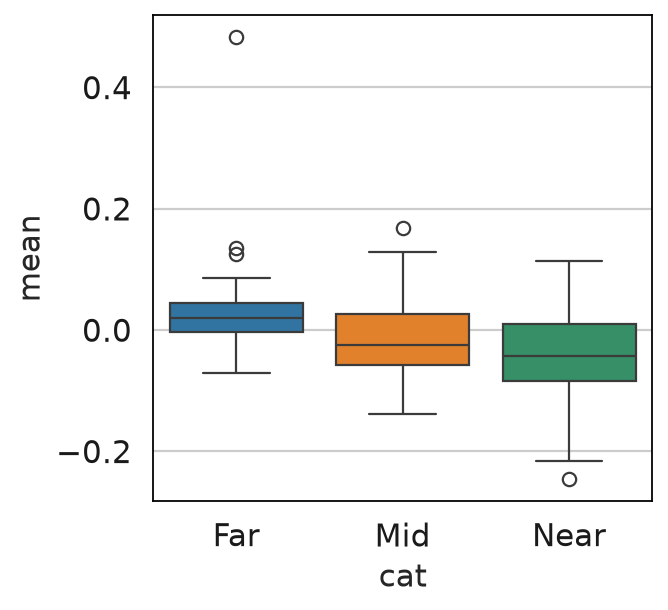

In [12]:
sc.set_figure_params(figsize=(4, 4))
sns.boxplot(data=sig_df, x='cat', y='mean', hue='cat')